Device: cpu


100%|██████████| 3.55M/3.55M [00:01<00:00, 2.59MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/rtatman/questionanswer-dataset/versions/1

Dataset shape: (4163, 9)
Columns: ['ï»¿articletitle', 'question', 'answer', 'difficultyfromquestioner', 'difficultyfromanswerer', 'articlefile', 'words', 'file', 'articletitle']
   ï»¿articletitle                                           question answer  \
0  Abraham_Lincoln  Was Abraham Lincoln the sixteenth President of...    yes   
1  Abraham_Lincoln  Was Abraham Lincoln the sixteenth President of...   Yes.   
2  Abraham_Lincoln  Did Lincoln sign the National Banking Act of 1...    yes   
3  Abraham_Lincoln  Did Lincoln sign the National Banking Act of 1...   Yes.   
4  Abraham_Lincoln                   Did his mother die of pneumonia?     no   

  difficultyfromquestioner difficultyfromanswerer  articlefile  words file  \
0                     easy                   easy  S08_set3_a4    NaN  NaN   
1                     easy                   easy  S08_set3_a4    NaN  NaN   
2        

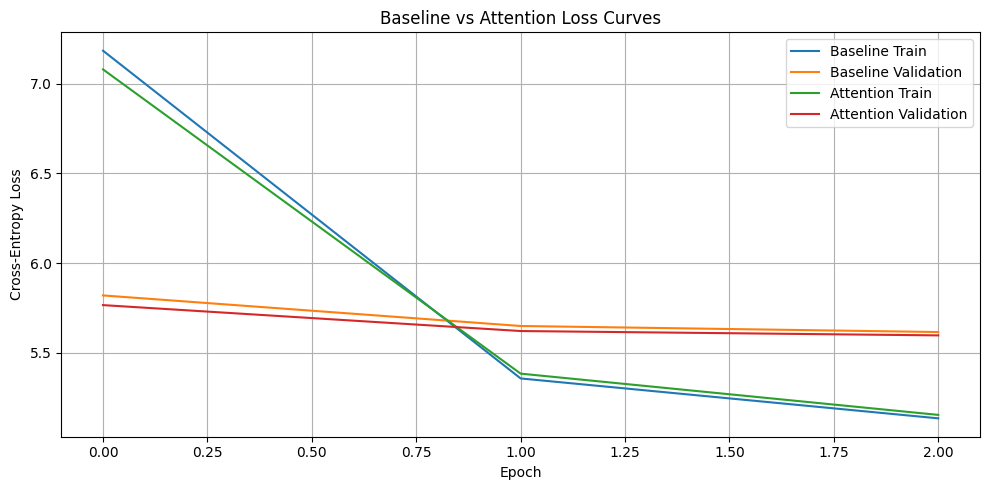

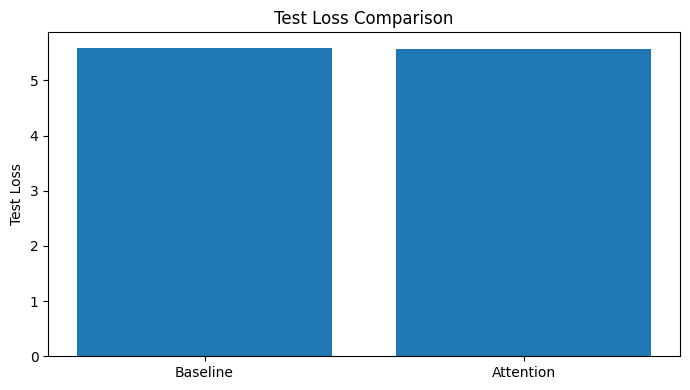


Question: What is the capital of France?
Baseline answer: yes
Attention answer: yes

Question: Who wrote Romeo and Juliet?
Baseline answer: yes
Attention answer: yes

Question: What is machine learning?
Baseline answer: yes
Attention answer: yes

Sample test predictions:

Question: Is Egypt bordered by the Gaza Strip?
Actual answer: Yes
Generated answer: yes

Question: Are most eels predators?
Actual answer: Yes, most eels are predators.
Generated answer: yes

Question: When did Proto-Uralic language arrive in Finland?
Actual answer: Around 1900 BCE
Generated answer: yes

Question: How long is a leopard's tail?
Actual answer: 60-110cm
Generated answer: yes

Question: Were ancient mallets made of copper?
Actual answer: no
Generated answer: yes

Assignment execution completed.


In [22]:

# ============================================================
# ATTENTION MECHANISMS IN PYTORCH
# Dataset: Question Answer Dataset (Kaggle)
# Task: Question-to-answer generation
# Comparison: Seq2Seq baseline vs Seq2Seq with attention
# ============================================================

# 1. INSTALL LIBRARIES

!pip install -q kagglehub

import os
import re
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")
print("Device:", device)


# 2. DOWNLOAD DATASET DIRECTLY FROM KAGGLE

import kagglehub

dataset_path = kagglehub.dataset_download(
    "rtatman/questionanswer-dataset"
)

print("Dataset downloaded to:", dataset_path)


# 3. FIND AND LOAD DATA FILES

# This dataset may contain tab-separated text files.
# Read supported CSV and TSV/TXT files automatically.

frames = []

for root, dirs, files in os.walk(dataset_path):
    for filename in files:
        filepath = os.path.join(root, filename)

        try:
            if filename.lower().endswith(".csv"):
                temp = pd.read_csv(
                    filepath, encoding="latin-1"
                )
                if len(temp.columns) >= 2:
                    frames.append(temp)

            elif filename.lower().endswith((".txt", ".tsv")):
                temp = pd.read_csv(
                    filepath,
                    sep="\t",
                    encoding="latin-1",
                    on_bad_lines="skip"
                )

                if len(temp.columns) >= 2:
                    frames.append(temp)

        except Exception as e:
            print("Skipping:", filename, "|", str(e)[:100])

if not frames:
    raise RuntimeError(
        "No readable CSV/TSV files found. "
        "Check the downloaded dataset files."
    )

df = pd.concat(frames, ignore_index=True)
df.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in df.columns
]

print("\nDataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())


# 4. IDENTIFY QUESTION AND ANSWER COLUMNS

# Accommodate common column names in QA datasets.

question_candidates = [
    "question", "questions", "question_text", "query"
]

answer_candidates = [
    "answer", "answers", "answer_text", "response"
]

question_col = next(
    (c for c in question_candidates if c in df.columns),
    None
)

answer_col = next(
    (c for c in answer_candidates if c in df.columns),
    None
)

if question_col is None or answer_col is None:
    raise ValueError(
        "Question/answer columns could not be identified. "
        "Available columns: " + str(df.columns.tolist())
    )

df = df[[question_col, answer_col]].copy()
df.columns = ["question", "answer"]

df = df.dropna()
df["question"] = df["question"].astype(str).str.strip()
df["answer"] = df["answer"].astype(str).str.strip()

df = df[
    (df["question"] != "") &
    (df["answer"] != "")
].drop_duplicates().reset_index(drop=True)

# Limit rows to make CPU training manageable.
SAMPLE_SIZE = 3000

if len(df) > SAMPLE_SIZE:
    df = df.sample(
        n=SAMPLE_SIZE, random_state=SEED
    ).reset_index(drop=True)

print("\nClean dataset shape:", df.shape)
print(df.head())


# 5. TEXT PREPROCESSING

PAD = "<pad>"
SOS = "<sos>"
EOS = "<eos>"
UNK = "<unk>"

MAX_VOCAB = 10000
MAX_LEN = 20

def tokenize(text):
    text = str(text).lower()
    return re.findall(r"[a-z0-9]+|[^\w\s]", text)

# Split the data before constructing the vocabulary.
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED
)

counter = Counter()

for text in train_df["question"]:
    counter.update(tokenize(text))

for text in train_df["answer"]:
    counter.update(tokenize(text))

vocab = {
    PAD: 0,
    SOS: 1,
    EOS: 2,
    UNK: 3
}

for word, _ in counter.most_common(MAX_VOCAB - len(vocab)):
    vocab[word] = len(vocab)

id_to_word = {v: k for k, v in vocab.items()}

def encode(text):
    tokens = tokenize(text)[:MAX_LEN - 1]
    ids = [vocab.get(t, vocab[UNK]) for t in tokens]
    return [vocab[SOS]] + ids + [vocab[EOS]]

def pad_sequence(ids):
    ids = ids[:MAX_LEN]
    return ids + [vocab[PAD]] * (MAX_LEN - len(ids))

print("Vocabulary size:", len(vocab))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


# 6. CREATE PYTORCH DATASET

class QADataset(Dataset):

    def __init__(self, frame):
        self.questions = [
            pad_sequence(encode(x))
            for x in frame["question"]
        ]

        self.answers = [
            pad_sequence(encode(x))
            for x in frame["answer"]
        ]

    def __len__(self):
        return len(self.questions)

    def __getitem__(self, idx):
        return (
            torch.tensor(
                self.questions[idx], dtype=torch.long
            ),
            torch.tensor(
                self.answers[idx], dtype=torch.long
            )
        )


BATCH_SIZE = 32

train_loader = DataLoader(
    QADataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    QADataset(val_df),
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    QADataset(test_df),
    batch_size=BATCH_SIZE
)


# 7. SEQ2SEQ MODEL WITH OPTIONAL ATTENTION

class Seq2Seq(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_dim=64,
        use_attention=False
    ):
        super().__init__()

        self.use_attention = use_attention
        self.hidden_dim = hidden_dim

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=vocab[PAD]
        )

        self.encoder = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.decoder = nn.LSTM(
            embedding_dim + (
                hidden_dim if use_attention else 0
            ),
            hidden_dim,
            batch_first=True
        )

        if use_attention:
            self.attn_encoder = nn.Linear(
                hidden_dim, hidden_dim, bias=False
            )
            self.attn_decoder = nn.Linear(
                hidden_dim, hidden_dim, bias=False
            )
            self.attn_score = nn.Linear(
                hidden_dim, 1, bias=False
            )

        self.output_layer = nn.Linear(
            hidden_dim, vocab_size
        )

    def forward(self, src, tgt):

        src_mask = src != vocab[PAD]

        enc_emb = self.embedding(src)
        enc_outputs, (hidden, cell) = self.encoder(enc_emb)

        dec_input = tgt[:, :-1]
        dec_emb = self.embedding(dec_input)

        outputs = []

        # Decode one token at a time to calculate attention.
        for t in range(dec_emb.size(1)):

            current_emb = dec_emb[:, t:t+1, :]

            if self.use_attention:

                # Additive attention scores
                query = self.attn_decoder(
                    hidden[-1]
                ).unsqueeze(1)

                keys = self.attn_encoder(enc_outputs)

                scores = self.attn_score(
                    torch.tanh(keys + query)
                ).squeeze(-1)

                scores = scores.masked_fill(
                    ~src_mask, -1e9
                )

                weights = torch.softmax(scores, dim=1)

                context = torch.bmm(
                    weights.unsqueeze(1),
                    enc_outputs
                )

                decoder_input = torch.cat(
                    [current_emb, context], dim=-1
                )

            else:
                decoder_input = current_emb

            dec_output, (hidden, cell) = self.decoder(
                decoder_input, (hidden, cell)
            )

            logits = self.output_layer(dec_output)
            outputs.append(logits)

        return torch.cat(outputs, dim=1)

    def generate(self, question, max_len=MAX_LEN):

        self.eval()

        ids = encode(question)
        src = torch.tensor(
            [pad_sequence(ids)],
            dtype=torch.long,
            device=device
        )

        with torch.no_grad():

            enc_outputs, (hidden, cell) = self.encoder(
                self.embedding(src)
            )

            src_mask = src != vocab[PAD]

            token = torch.tensor(
                [[vocab[SOS]]],
                dtype=torch.long,
                device=device
            )

            generated = []

            for _ in range(max_len):

                current_emb = self.embedding(token)

                if self.use_attention:

                    query = self.attn_decoder(
                        hidden[-1]
                    ).unsqueeze(1)

                    keys = self.attn_encoder(enc_outputs)

                    scores = self.attn_score(
                        torch.tanh(keys + query)
                    ).squeeze(-1)

                    scores = scores.masked_fill(
                        ~src_mask, -1e9
                    )

                    weights = torch.softmax(scores, dim=1)

                    context = torch.bmm(
                        weights.unsqueeze(1),
                        enc_outputs
                    )

                    decoder_input = torch.cat(
                        [current_emb, context], dim=-1
                    )
                else:
                    decoder_input = current_emb

                dec_output, (hidden, cell) = self.decoder(
                    decoder_input, (hidden, cell)
                )

                logits = self.output_layer(dec_output)

                next_id = logits.argmax(
                    dim=-1
                ).item()

                if next_id == vocab[EOS]:
                    break

                if next_id not in (
                    vocab[PAD], vocab[SOS]
                ):
                    generated.append(
                        id_to_word.get(next_id, UNK)
                    )

                token = torch.tensor(
                    [[next_id]],
                    dtype=torch.long,
                    device=device
                )

        return " ".join(generated)


# 8. TRAINING FUNCTION

def train_model(model, epochs=3, lr=0.001):

    model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr
    )

    criterion = nn.CrossEntropyLoss(
        ignore_index=vocab[PAD]
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):

        model.train()
        total_train_loss = 0

        for src, tgt in train_loader:

            src = src.to(device)
            tgt = tgt.to(device)

            optimizer.zero_grad()

            logits = model(src, tgt)

            # The decoder predicts the next answer token.
            targets = tgt[:, 1:]

            loss = criterion(
                logits.reshape(-1, len(vocab)),
                targets.reshape(-1)
            )

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_train_loss += (
                loss.item() * src.size(0)
            )

        train_loss = (
            total_train_loss / len(train_loader.dataset)
        )

        model.eval()
        total_val_loss = 0

        with torch.no_grad():

            for src, tgt in val_loader:

                src = src.to(device)
                tgt = tgt.to(device)

                logits = model(src, tgt)
                targets = tgt[:, 1:]

                loss = criterion(
                    logits.reshape(-1, len(vocab)),
                    targets.reshape(-1)
                )

                total_val_loss += (
                    loss.item() * src.size(0)
                )

        val_loss = (
            total_val_loss / len(val_loader.dataset)
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
        )

    return model, history


# 9. TRAIN BASELINE MODEL

print("\nTraining baseline Seq2Seq model...")

baseline = Seq2Seq(
    len(vocab),
    use_attention=False
)

baseline, baseline_history = train_model(
    baseline, epochs=3
)


# 10. TRAIN ATTENTION MODEL

print("\nTraining attention-based Seq2Seq model...")

attention_model = Seq2Seq(
    len(vocab),
    use_attention=True
)

attention_model, attention_history = train_model(
    attention_model, epochs=3
)


# 11. EVALUATE USING TEST LOSS

def test_loss(model, loader):

    model.eval()

    criterion = nn.CrossEntropyLoss(
        ignore_index=vocab[PAD]
    )

    total_loss = 0

    with torch.no_grad():

        for src, tgt in loader:

            src = src.to(device)
            tgt = tgt.to(device)

            logits = model(src, tgt)
            targets = tgt[:, 1:]

            loss = criterion(
                logits.reshape(-1, len(vocab)),
                targets.reshape(-1)
            )

            total_loss += loss.item() * src.size(0)

    return total_loss / len(loader.dataset)


baseline_test_loss = test_loss(
    baseline, test_loader
)

attention_test_loss = test_loss(
    attention_model, test_loader
)

print("\nTest Results")
print("Baseline test loss:", round(baseline_test_loss, 4))
print("Attention test loss:", round(attention_test_loss, 4))


# 12. PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    baseline_history["train_loss"],
    label="Baseline Train"
)
plt.plot(
    baseline_history["val_loss"],
    label="Baseline Validation"
)
plt.plot(
    attention_history["train_loss"],
    label="Attention Train"
)
plt.plot(
    attention_history["val_loss"],
    label="Attention Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Baseline vs Attention Loss Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 13. COMPARE TEST LOSS

plt.figure(figsize=(7, 4))

plt.bar(
    ["Baseline", "Attention"],
    [baseline_test_loss, attention_test_loss]
)

plt.ylabel("Test Loss")
plt.title("Test Loss Comparison")
plt.tight_layout()
plt.show()


# 14. GENERATE ANSWERS

for question in [
    "What is the capital of France?",
    "Who wrote Romeo and Juliet?",
    "What is machine learning?"
]:

    print("\nQuestion:", question)

    print(
        "Baseline answer:",
        baseline.generate(question)
    )

    print(
        "Attention answer:",
        attention_model.generate(question)
    )


# 15. SHOW ACTUAL ANSWER VS GENERATED ANSWER

print("\nSample test predictions:")

for i in range(min(5, len(test_df))):

    question = test_df.iloc[i]["question"]
    actual_answer = test_df.iloc[i]["answer"]

    predicted_answer = attention_model.generate(
        question
    )

    print("\nQuestion:", question)
    print("Actual answer:", actual_answer)
    print("Generated answer:", predicted_answer)


# 16. SAVE THE TRAINED MODELS

torch.save(
    baseline.state_dict(),
    "baseline_seq2seq.pth"
)

torch.save(
    attention_model.state_dict(),
    "attention_seq2seq.pth"
)

print("\nAssignment execution completed.")
